# Calibration, decision bands, explanations and fairness

Phase 5. The model stops being a ranking and becomes a decision: every
activation is auto-released, sent to a human, or refused.

**What changed in how results are reported.** Seed 42 is no longer the headline.
Every number here is a mean across seeds 7, 42, 101 and 2024 with the
seed-level spread beside it. Fold-level spread appears only as a secondary
figure, and it understates uncertainty: `StratifiedGroupKFold` orders groups by
size, so fold 0 always carries the heaviest agents and the folds are not
exchangeable.

**What changed in the model.** The matched-strength sweep in Phase 4 put every
resampling method within 0.004 PR-AUC of every other against a fold standard
deviation of 0.037, with no handling scoring highest. The chosen model is
therefore XGBoost on the T7 feature set with **no resampling and no class
weighting**. The pre-registered Phase 3 choice (SMOTE at a minority ratio of
0.30) is trained and reported alongside: it scores 0.703 against 0.712, a gap of
0.009 against a seed-level spread of 0.034, so the deviation costs nothing
measurable and the sweep's conclusion holds.

**What changed in the training loop.** Each fold's training split is divided by
agent: the model is fitted on one part and the probability calibrator on the
other, which the model has never seen. The model therefore trains on about three
quarters of the rows it used in Phase 4, which is the price of an honest
calibrator. PR-AUC here (0.712) is not comparable with the Phase 4 seed-42
figure (0.781): different seeds, fewer training rows, one repeat instead of
three.

Nothing here is tuned toward a metric. `config/costs.yaml` was written before
the bands were optimised, and the calibration method was chosen by a rule fixed
in advance.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

OUT = REPO_ROOT / "outputs"
FIGURES = OUT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 150)

read = lambda name: pd.read_csv(OUT / f"{name}.csv")
calibration = read("calibration_summary")
choice = read("calibration_choice")
curves = read("calibration_reliability_curves")
auto_release = read("auto_release_summary")
auto_release_gap = read("auto_release_t0_vs_t7")
operating = read("band_operating_point")
surface = read("band_cost_surface")
sensitivity = read("band_sensitivity")
staffing = read("band_staffing")
baselines = read("band_baselines")
costs = read("cost_matrix")
shap_global = read("shap_global_importance")
shap_typology = read("shap_importance_by_typology")
shap_shares = read("shap_agent_history_share")
shap_cases = read("shap_worked_cases")
fair_honesty = read("fairness_bands_by_honesty")
fair_situation = read("fairness_bands_by_situation")
fair_delay = read("fairness_expected_delay")
fair_queue = read("fairness_queue")
audit_stability = read("lookalike_audit_stability")
seed_summary = read("multiseed_seed_summary")

METHOD = choice["chosen_method"].iloc[0]
RELEASE = float(operating["release_threshold"].iloc[0])
REJECT = float(operating["reject_threshold"].iloc[0])

SURFACE, INK, INK_2, MUTED, GRID, BASELINE = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SLOTS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": BASELINE, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK_2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "grid.linestyle": "-",
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "lines.linewidth": 2.0, "legend.frameon": False, "font.size": 10, "axes.titlesize": 11,
})
print(f"seeds: {sorted(seed_summary['seed'])}")
print(f"calibration: {METHOD}; bands: release <= {RELEASE:.4f}, reject > {REJECT:.4f}")

seeds: [7, 42, 101, 2024]
calibration: isotonic; bands: release <= 0.2667, reject > 0.6667


## The four datasets

In [2]:
seed_summary.round(4)

,seed,activations,realised_fraud_rate,days,mean_daily_activations,mean_commission_value_kes
0,7,89325,0.0701,180,496.250,81.3701
1,42,90533,0.0735,180,502.961,81.1948
2,101,91944,0.0723,180,510.800,81.3951
3,2024,94675,0.0716,180,525.972,81.2194


## The lookalike audit, now across every seed

The standing rule from the Phase 4 review, now in CLAUDE.md: a missing
counterpart is real only if it is stable across realisations. A signature
flagged at one seed and not the others is noise and must not be fixed.

**Result: no defects.** No signature is flagged at all four seeds. The sim
farming device-sharing flag that surfaced in Phase 4 appears at exactly one seed
of four, with a legitimate share ranging from 1.0% to 4.2% depending on the
draw. Under the new rule it is noise, and it is not fixed.

In [3]:
flagged = audit_stability[audit_stability["seeds_flagged"] > 0]
print(f"signatures flagged at one or more of the {int(audit_stability['seeds_audited'].iloc[0])} seeds: {len(flagged)}")
print(f"defects (flagged at every seed): {(audit_stability['verdict'].str.startswith('defect')).sum()}")
flagged[["typology", "feature", "seeds_flagged", "legitimate_share_min", "legitimate_share_mean",
         "legitimate_share_max", "fraud_purity_mean", "verdict"]].round(5)

signatures flagged at one or more of the 4 seeds: 1
defects (flagged at every seed): 0


,typology,feature,seeds_flagged,legitimate_share_min,legitimate_share_mean,legitimate_share_max,fraud_purity_mean,verdict
0,sim_farming,device_shared_agent_count_30d,1,0.00998,0.02787,0.04196,0.3179,noise: flagged at some seeds only


## The cost matrix

All costs in units of one agent commission, so the optimisation holds whatever a
commission is worth. `review` and `review_capacity_daily_share` are computed
from their parts rather than assumed.

Two things to carry into everything downstream:

- **The computed review cost is 0.576, not the 0.45 in the brief.** The
  components given (9 minutes, KSh 55,000 a month, 176 hours, KSh 312.50 an
  hour) divided by the generator's implied commission value of KSh 81.34
  produce 0.576. It sits inside the stated 0.25 to 0.70 range, the computed
  value is what the optimisation uses, and the sensitivity analysis sweeps the
  whole range, so both values are covered.
- **`commission_value_kes` is the least-sourced number in the file.** It comes
  from the generator's assumed escrow distribution, not from an industry
  partner, and the review cost scales inversely with it. If a real commission is
  worth more than KSh 81, review is cheaper than modelled and the review band
  should be wider than the one chosen below.

In [4]:
costs.round(4)

,quantity,value,unit,derivation
0,commission,1.0000,commission,the unit of account
1,false_negative,2.5000,commissions,"commission paid on non-existent work, unrecove..."
2,false_positive_review,0.0500,commissions,residual harm of the delay itself; Phase 5 mea...
3,false_positive_reject,3.0000,commissions,"refusing honest earnings: lost commission, dis..."
4,review_sensitivity,0.8500,probability,P(a review catches fraud); a miss costs false_...
5,review_specificity,0.9500,probability,P(a review clears honest work); a wrong refusa...
6,cost of a reviewed fraudulent activation,0.9513,commissions,review 0.576 + (1 - 0.85) x 2.5
7,cost of a reviewed genuine activation,0.7763,commissions,review 0.576 + delay 0.05 + (1 - 0.95) x 3.0
8,loaded_hourly_rate_kes,312.5000,KSh per hour,55000 KSh per month / 176 hours
9,commission_value_kes,81.3400,KSh,generator mean escrow times commission_rate; l...


## Part B: calibration

The bands are probability cutoffs, so the scores feeding them have to mean what
they say. Each calibrator is fitted inside the training window on agents the
model never saw, and never on test data. Expected calibration error uses
equal-count bins, because calibrated fraud probabilities pile up near zero and
equal-width bins would put almost everything in the first one.

**Chosen: isotonic**, by a rule fixed before the numbers were seen (lowest ECE,
Brier breaking a tie inside one seed-level standard deviation).

- Isotonic more than halves ECE against the raw scores: **0.0067 against 0.0105**.
- **Platt scaling makes calibration worse than doing nothing** (ECE 0.0212). The sigmoid is too rigid for this score distribution, which is dense near zero with a long thin tail.
- The raw scores were already reasonably calibrated, which is what an XGBoost model fitted without resampling should look like: nothing has distorted the class balance it was trained on.

**Part B5.** PR-AUC moves by -0.006 (0.718 to 0.712), against a fold-level
standard deviation of 0.053. Both mappings are monotone, so ranking cannot
change except through ties; isotonic creates ties, which is the entire effect.
Nothing to investigate.

In [5]:
calibration[["method", "brier_mean", "brier_sd_across_seeds", "ece_mean", "ece_sd_across_seeds",
             "pr_auc_mean", "pr_auc_sd_across_seeds", "pr_auc_sd_across_folds",
             "mean_predicted", "observed_fraud_rate"]].round(5)

,method,brier_mean,brier_sd_across_seeds,ece_mean,ece_sd_across_seeds,pr_auc_mean,pr_auc_sd_across_seeds,pr_auc_sd_across_folds,mean_predicted,observed_fraud_rate
0,isotonic,0.03513,0.00179,0.00671,0.00285,0.71199,0.03387,0.05334,0.06718,0.07283
1,sigmoid,0.03625,0.00182,0.02124,0.00154,0.71172,0.03296,0.05129,0.06937,0.07283
2,uncalibrated,0.03514,0.00169,0.01045,0.00436,0.71832,0.03213,0.05129,0.06283,0.07283


In [6]:
choice.T

,0
chosen_method,isotonic
rule,lowest ECE; Brier breaks ties within one seed-...
ece,0.006707
ece_uncalibrated,0.010445
brier,0.03513
brier_uncalibrated,0.035136
pr_auc,0.711992
pr_auc_uncalibrated,0.718318
pr_auc_change,-0.006325
pr_auc_sd_across_seeds,0.032131


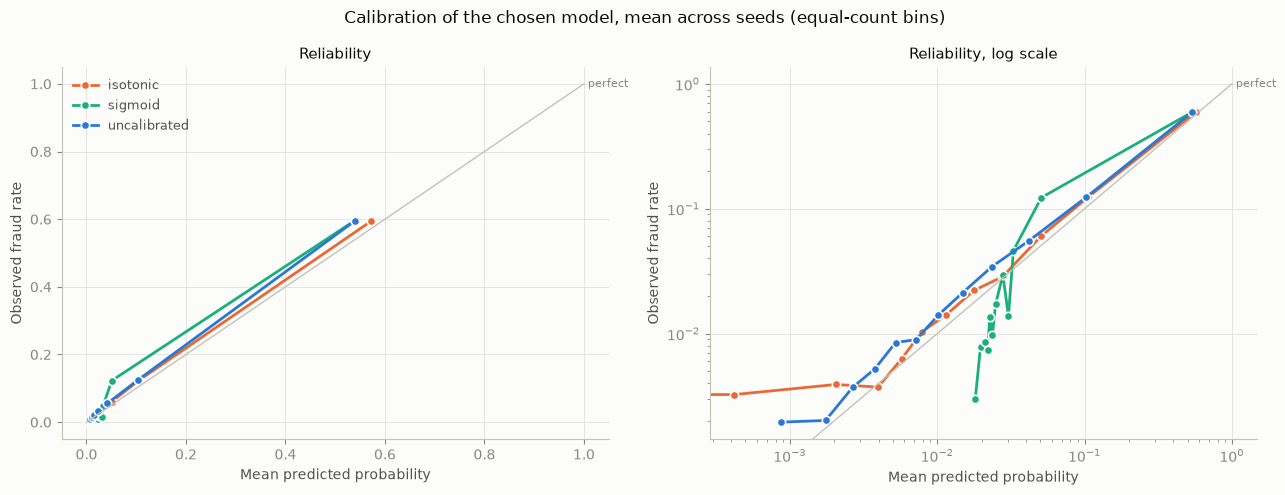

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
colour = dict(zip(["uncalibrated", "isotonic", "sigmoid"], SLOTS))
mean_curve = curves.groupby(["method", "bin"])[["mean_predicted", "observed_fraud_rate"]].mean().reset_index()

for axis, (scale, title) in zip(axes, [("linear", "Reliability"), ("log", "Reliability, log scale")]):
    for method, group in mean_curve.groupby("method"):
        group = group.sort_values("mean_predicted")
        axis.plot(group["mean_predicted"], group["observed_fraud_rate"], marker="o", markersize=6,
                  markeredgecolor=SURFACE, markeredgewidth=1.2, color=colour[method], label=method)
    limit = [mean_curve["mean_predicted"].min() * 0.8 if scale == "log" else 0, 1.0]
    axis.plot(limit, limit, color=BASELINE, linewidth=1)
    axis.text(limit[1], limit[1], " perfect", color=MUTED, fontsize=8, va="center")
    axis.set(xscale=scale, yscale=scale, xlabel="Mean predicted probability",
             ylabel="Observed fraud rate", title=title)
axes[0].legend(fontsize=9, loc="upper left")
fig.suptitle(f"Calibration of the chosen model, mean across seeds (equal-count bins)", color=INK, fontsize=12)
fig.tight_layout()
fig.savefig(FIGURES / "reliability_curves.png", dpi=120)
plt.show()

## Part C: what the hold window actually buys

PR-AUC averages over every threshold, including regions no escrow system would
operate in. Auto-release lives at one end: a payout clears without a human only
where the released set is nearly all genuine.

**Read the 95% row with care.** Prevalence is 7.3%, so releasing every
activation untouched already gives a released set that is 92.7% genuine. The 95%
bar is barely above doing nothing, and both models clear it while releasing
about 97.5% of volume, letting roughly two thirds of all fraud through. It is
not a serious operating point; it is included because it was asked for.

**The 99% row is the real comparison, and the T7 advantage is much larger there
than PR-AUC suggests.**

In [8]:
auto_release[["model", "released_precision_target", "auto_released_share_mean",
              "auto_released_share_sd_across_seeds", "review_queue_share_mean",
              "fraud_released_share_of_all_fraud_mean", "fraud_value_released_share_mean",
              "threshold_mean"]].round(4)

,model,released_precision_target,auto_released_share_mean,auto_released_share_sd_across_seeds,review_queue_share_mean,fraud_released_share_of_all_fraud_mean,fraud_value_released_share_mean,threshold_mean
0,t0_none,0.95,0.9739,0.0050,0.0261,0.6767,0.6764,0.6712
1,t0_none,0.99,0.5739,0.0583,0.4261,0.0824,0.0825,0.0215
2,t7_none,0.95,0.9750,0.0037,0.0250,0.6715,0.6720,0.8244
3,t7_none,0.99,0.7329,0.0400,0.2671,0.1020,0.1018,0.0349


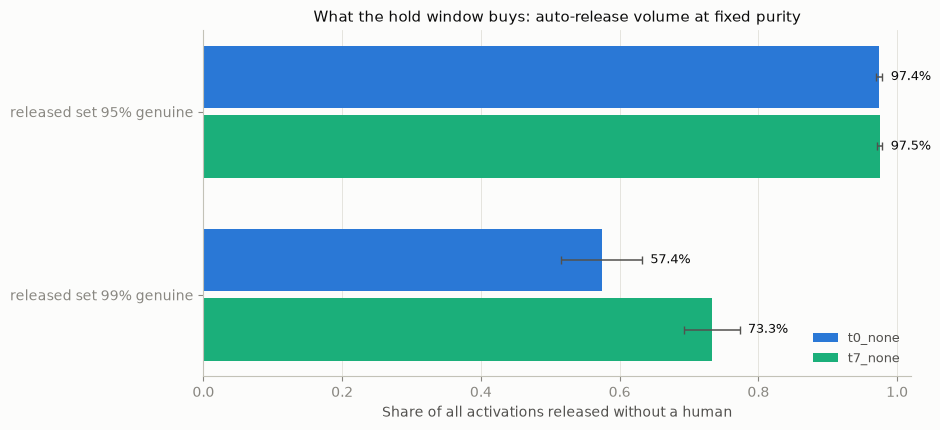

In [9]:
fig, axis = plt.subplots(figsize=(9.5, 4.4))
models = sorted(auto_release["model"].unique())
colour = dict(zip(models, [SLOTS[0], SLOTS[2]]))
targets = sorted(auto_release["released_precision_target"].unique())
base = np.arange(len(targets))[::-1]
for offset, model in zip((0.19, -0.19), models):
    rows = auto_release[auto_release["model"] == model].set_index("released_precision_target").reindex(targets)
    axis.barh(base + offset, rows["auto_released_share_mean"], height=0.34, color=colour[model],
              xerr=rows["auto_released_share_sd_across_seeds"],
              error_kw={"ecolor": INK_2, "elinewidth": 1.1, "capsize": 3}, label=model)
    for y, value, sd in zip(base + offset, rows["auto_released_share_mean"], rows["auto_released_share_sd_across_seeds"]):
        axis.text(value + (sd if np.isfinite(sd) else 0) + 0.012, y, f"{value:.1%}", va="center", fontsize=9, color=INK)
axis.set_yticks(base, [f"released set {t:.0%} genuine" for t in targets])
axis.set(xlabel="Share of all activations released without a human", xlim=(0, 1.02),
         title="What the hold window buys: auto-release volume at fixed purity")
axis.grid(axis="y", visible=False)
axis.legend(fontsize=9, loc="lower right")
fig.tight_layout()
fig.savefig(FIGURES / "auto_release.png", dpi=120)
plt.show()

In [10]:
auto_release_gap.round(4)

,released_precision_target,t7_auto_released_share,t0_auto_released_share,difference,relative_gain,t7_review_queue_share,t0_review_queue_share,t7_fraud_value_released_share,t0_fraud_value_released_share
0,0.95,0.9750,0.9739,0.0011,0.0011,0.0250,0.0261,0.6720,0.6764
1,0.99,0.7329,0.5739,0.1589,0.2769,0.2671,0.4261,0.1018,0.0825


## Part D: where to put the bands

**The cost model was corrected after Phase 5.** Two changes, both from the
supervisor, and both of which move the answer:

1. **The false positive is split by band.** Delaying a genuine activation in the queue and refusing its payout outright are not the same act. Phase 5 priced them identically at 1.0 commission, which told the optimiser that a nine-minute delay and a refusal were equivalent, and pushed honest work toward the more harmful band. They are now 0.05 for the delay and **3.0 for a refusal**, the latter set deliberately **above** the cost of paying out on a fraud (2.5) as a stated value judgement about whose money it is.
2. **Reviews are no longer assumed correct.** A review catches fraud 85% of the time and clears honest work 95% of the time, and a review that gets it wrong pays for the mistake it makes.

Expected cost per activation is now

    P(released and fraudulent) x false_negative
  + P(reviewed and fraudulent) x [review + (1 - sensitivity) x false_negative]
  + P(reviewed and genuine)    x [review + delay + (1 - specificity) x false_positive_reject]
  + P(rejected and genuine)    x false_positive_reject

A reviewed genuine activation now costs 0.776 and a reviewed fraudulent one
0.951, against a flat 0.576 in Phase 5, so review is a dearer instrument than it
looked. The surface is computed per seed and averaged.

In [11]:
operating.T

,0,1
variant,chosen (capacity constrained),unconstrained
release_threshold,0.266667,0.266667
reject_threshold,0.666667,0.666667
expected_cost_per_activation,0.106358,0.106358
expected_cost_sd_across_seeds,0.004685,0.004685
released_share,0.937244,0.937244
review_share,0.029601,0.029601
reject_share,0.033155,0.033155
reject_precision,0.910377,0.910377
reject_recall,0.413438,0.413438


In [12]:
baselines.round(4)

,policy,expected_cost,review_share
0,release everything,0.1820,0
1,review everything,0.7890,1
2,reject everything,2.7816,0


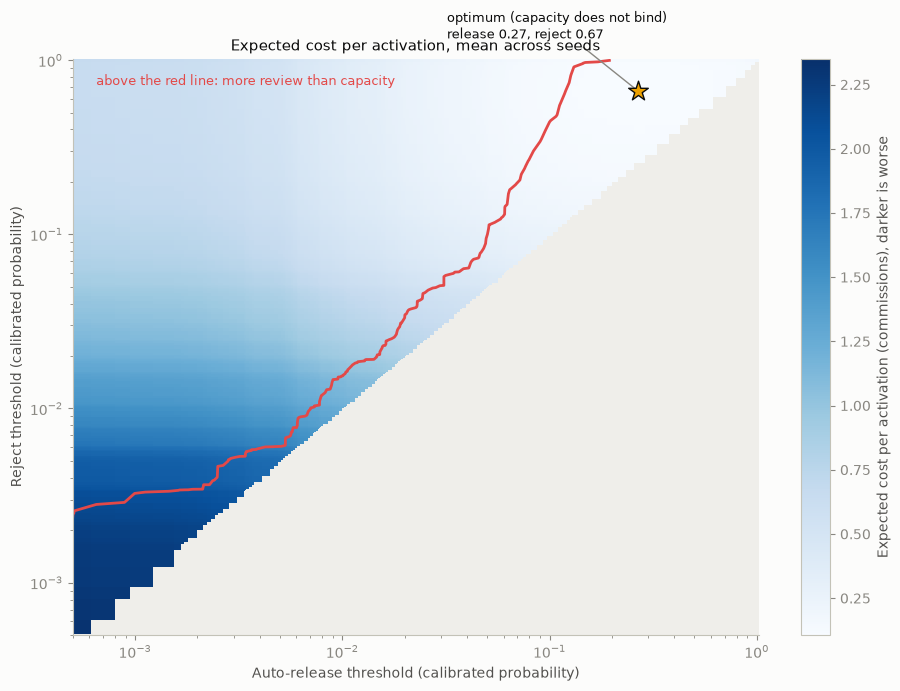

In [13]:
grid_release = np.sort(surface["release_threshold"].unique())
grid_reject = np.sort(surface["reject_threshold"].unique())
pivot = surface.pivot_table(index="reject_threshold", columns="release_threshold", values="expected_cost")
feasible = surface.pivot_table(index="reject_threshold", columns="release_threshold", values="review_share")
capacity = float(operating["capacity_share"].iloc[0])

fig, axis = plt.subplots(figsize=(9.5, 7))
colours = plt.get_cmap("Blues").copy()
colours.set_bad("#efeeea")  # pairs where release > reject: not a valid policy
mesh = axis.pcolormesh(pivot.columns, pivot.index, np.ma.masked_invalid(pivot.to_numpy()),
                       shading="nearest", cmap=colours)
bar = fig.colorbar(mesh, ax=axis)
bar.set_label("Expected cost per activation (commissions), darker is worse", color=INK_2)

# Everything above the red line sends more to review than one reviewer can take.
axis.contourf(feasible.columns, feasible.index, feasible.to_numpy(), levels=[capacity, 1.0],
              colors=["none"], hatches=["////"], alpha=0.0)
axis.contour(feasible.columns, feasible.index, feasible.to_numpy(), levels=[capacity],
             colors=["#e34948"], linewidths=2)
unconstrained = operating[operating["variant"] == "unconstrained"].iloc[0]
same_point = (abs(unconstrained["release_threshold"] - RELEASE) < 1e-12
              and abs(unconstrained["reject_threshold"] - REJECT) < 1e-12)
axis.scatter([RELEASE], [REJECT], s=220, marker="*", color="#eda100", edgecolor=INK, zorder=5)
note = "optimum" if not same_point else "optimum (capacity does not bind)"
axis.annotate(f"{note}\nrelease {RELEASE:.2f}, reject {REJECT:.2f}", xy=(RELEASE, REJECT),
              xytext=(RELEASE * 0.12, REJECT * 2.0), color=INK, fontsize=9,
              arrowprops={"arrowstyle": "-", "color": MUTED, "linewidth": 1})
if not same_point:
    axis.scatter([unconstrained["release_threshold"]], [unconstrained["reject_threshold"]], s=90,
                 marker="o", color=SURFACE, edgecolor=INK, zorder=5)
axis.text(pivot.columns.min() * 1.3, pivot.index.max() * 0.72,
          "above the red line: more review than capacity", color="#e34948", fontsize=9)
axis.set(xscale="log", yscale="log", xlabel="Auto-release threshold (calibrated probability)",
         ylabel="Reject threshold (calibrated probability)",
         title="Expected cost per activation, mean across seeds")
axis.grid(visible=False)
fig.tight_layout()
fig.savefig(FIGURES / "band_cost_surface.png", dpi=120)
plt.show()

### Part C3: what moved, and why

Both thresholds rose, and the reject band shrank by a third.

- **The reject threshold rose most (0.40 to 0.67)** because refusing a genuine activation now costs three times what it did. The optimiser demands much stronger evidence before refusing, so the reject band takes 3.3% of volume instead of 5.0%, and its precision rises from 0.79 to 0.91 while its recall falls from 0.54 to 0.41.
- **The release threshold rose too (0.21 to 0.27)**, because the middle band is dearer now that reviews can be wrong. Marginal activations are released rather than bought a review.
- **The price is more fraud paid out**: the share of all fraud auto-released rises from 34.5% to 39.7%, and expected cost per activation rises from 0.088 to 0.106 commissions.

That last number is not the system getting worse. It is the Phase 5 figure
having been too low, because it costed a refusal at a third of its stated value
and assumed reviewers never err.

In [14]:
comparison_point = read("comparison_operating_point")
comparison_point.round(5)

,quantity,phase5,phase6,change
0,release_threshold,0.20588,0.26667,0.06078
1,reject_threshold,0.39796,0.66667,0.26871
2,released_share,0.92470,0.93724,0.01254
3,review_share,0.02506,0.02960,0.00454
4,reject_share,0.05024,0.03316,-0.01708
5,reject_precision,0.78558,0.91038,0.12480
6,reject_recall,0.54132,0.41344,-0.12788
7,released_fraud_share_of_all_fraud,0.34461,0.39660,0.05198
8,expected_cost_per_activation,0.08797,0.10636,0.01839


## Part C4: does the answer survive the cost ranges?

Each parameter is moved to each end of its stated range, one at a time, then all
together as a best case and a worst case. The accuracy parameters are read the
other way round: their optimistic end is the high one.

**The bands still move a great deal, but the three-band structure now survives
everywhere.** In Phase 5 the middle band vanished entirely at a cheap false
positive or an expensive review; under the corrected model the narrowest it ever
gets is 0.8% of volume. Splitting the false positive is what saved it: review is
no longer competing against a rejection priced as though it were nearly
harmless.

In [15]:
sensitivity[["scenario", "false_negative", "false_positive_review", "false_positive_reject",
             "review", "review_sensitivity", "review_specificity", "capacity",
             "release_threshold", "reject_threshold", "release_shift", "reject_shift",
             "review_share", "reject_share", "expected_cost"]].round(4)

,scenario,false_negative,false_positive_review,false_positive_reject,review,review_sensitivity,review_specificity,capacity,release_threshold,reject_threshold,release_shift,reject_shift,review_share,reject_share,expected_cost
0,baseline,2.5,0.05,3.0,0.5763,0.85,0.950,0.0786,0.2667,0.6667,0.0000,0.0000,0.0296,0.0332,0.1064
1,false_negative low (1.5),1.5,0.05,3.0,0.5763,0.85,0.950,0.0786,0.4859,0.6667,0.2192,0.0000,0.0083,0.0332,0.0719
2,false_negative high (4.0),4.0,0.05,3.0,0.5763,0.85,0.950,0.0786,0.2059,0.6667,-0.0608,0.0000,0.0421,0.0332,0.1490
3,false_positive_review low (0.0),2.5,0.00,3.0,0.5763,0.85,0.950,0.0786,0.2667,0.6667,0.0000,0.0000,0.0296,0.0332,0.1056
4,false_positive_review high (0.3),2.5,0.30,3.0,0.5763,0.85,0.950,0.0786,0.3980,0.6667,0.1313,0.0000,0.0171,0.0332,0.1091
5,false_positive_reject low (1.5),2.5,0.05,1.5,0.5763,0.85,0.950,0.0786,0.2218,0.3980,-0.0448,-0.2687,0.0203,0.0502,0.0982
6,false_positive_reject high (6.0),2.5,0.05,6.0,0.5763,0.85,0.950,0.0786,0.3529,0.8356,0.0863,0.1690,0.0290,0.0250,0.1128
7,review low (0.25),2.5,0.05,3.0,0.2500,0.85,0.950,0.0786,0.1487,0.8356,-0.1180,0.1690,0.0665,0.0250,0.0919
8,review high (0.7),2.5,0.05,3.0,0.7000,0.85,0.950,0.0786,0.3529,0.6667,0.0863,0.0000,0.0208,0.0332,0.1092
9,review_sensitivity low (0.6),2.5,0.05,3.0,0.5763,0.60,0.950,0.0786,0.3980,0.5634,0.1313,-0.1033,0.0125,0.0377,0.1121


## Part C5: more reviewers

Still nothing. The optimum uses 2.96% of volume against a capacity of 7.86%, so
the second and third reviewer have nothing to do, and capacity does not appear
anywhere in the sensitivity table. Staffing is not the binding constraint; the
price and the accuracy of a review are.

In [16]:
staffing.round(4)

,reviewers,capacity_share,release_threshold,reject_threshold,expected_cost,review_share,reject_share,released_share,reject_precision,reject_recall
0,1,0.0786,0.2667,0.6667,0.1064,0.0296,0.0332,0.9372,0.9104,0.4134
1,2,0.1572,0.2667,0.6667,0.1064,0.0296,0.0332,0.9372,0.9104,0.4134
2,3,0.2358,0.2667,0.6667,0.1064,0.0296,0.0332,0.9372,0.9104,0.4134


## Part D: the design depends on an unsourced number

The review cost is `review_minutes * loaded_hourly_rate / commission_value_kes`,
so every band boundary scales inversely with the shilling value of a commission.
That value is currently KSh 81.34, taken from the generator's assumed escrow
distribution. No industry partner has supplied it.

**The middle band is empty at or below KSh 40 and opens from KSh 50 upward.** At
the assumed KSh 81 it takes 3.0% of volume; at KSh 200, 6.6%; at KSh 500, 7.5%,
where it begins to press against review capacity.

Stated plainly: the three-band design is viable only if a commission is worth
more than roughly KSh 50. Below that a review costs more than the errors it
prevents, and the rational policy is two bands, release or refuse, with no human
in the loop at all. The assumed value sits less than twice the collapse point
and rests on an assumed escrow distribution rather than a measurement. Before
this design is put to a client, the actual commission value is the first number
to obtain: at KSh 40 the recommendation changes shape entirely, and at KSh 300
the review band should be more than twice as wide as the one chosen here.

In [17]:
commission = read("commission_sweep")
collapse = read("commission_collapse_point")
display(commission[["commission_value_kes", "review_cost_commissions", "release_threshold", "reject_threshold",
                    "released_share", "review_share", "reject_share", "expected_cost"]].round(4))
collapse.round(2)

,commission_value_kes,review_cost_commissions,release_threshold,reject_threshold,released_share,review_share,reject_share,expected_cost
0,50,0.9375,0.3980,0.5634,0.9498,0.0125,0.0377,0.1127
1,100,0.4688,0.2218,0.6667,0.9295,0.0374,0.0332,0.1027
2,200,0.2344,0.1487,0.8356,0.9085,0.0665,0.0250,0.0908
3,350,0.1339,0.1310,0.8356,0.9003,0.0746,0.0250,0.0835
4,500,0.0938,0.1310,0.8356,0.9003,0.0746,0.0250,0.0805


,current_assumed_commission_value_kes,collapses_below_kes,highest_value_with_no_review_band_kes,note
0,81.34,50,40,the middle band is empty at or below the secon...


## Part E: what the model is looking at

SHAP values are computed during training for the chosen model on a sample of
each fold's test rows, so the explanation always belongs to the model that
produced the score. They explain the uncalibrated score; the calibrated
probability is a monotone function of it, so the ordering of reasons is
unaffected.

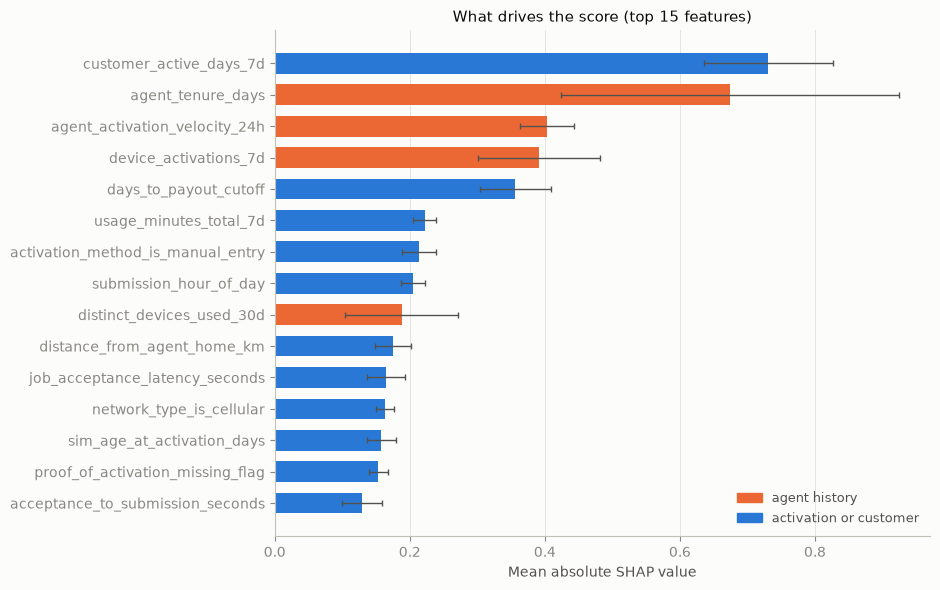

In [18]:
fig, axis = plt.subplots(figsize=(9.5, 6))
top = shap_global.head(15).iloc[::-1]
colours = [SLOTS[1] if group == "agent history" else SLOTS[0] for group in top["group"]]
positions = np.arange(len(top))
axis.barh(positions, top["mean_abs_shap"], height=0.66, color=colours,
          xerr=top["sd_across_seeds"], error_kw={"ecolor": INK_2, "elinewidth": 1.0, "capsize": 2})
axis.set_yticks(positions, top["feature"])
axis.set(xlabel="Mean absolute SHAP value", title="What drives the score (top 15 features)")
axis.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=SLOTS[1]), plt.Rectangle((0, 0), 1, 1, color=SLOTS[0])]
axis.legend(handles, ["agent history", "activation or customer"], fontsize=9, loc="lower right")
fig.tight_layout()
fig.savefig(FIGURES / "shap_global.png", dpi=120)
plt.show()

In [19]:
shap_typology.groupby("typology").head(5)[
    ["typology", "feature", "mean_abs_shap", "mean_signed_shap", "share_within_typology"]].round(4)

,typology,feature,mean_abs_shap,mean_signed_shap,share_within_typology
0,collusion,customer_active_days_7d,0.6736,0.3166,0.1343
1,collusion,agent_activation_velocity_24h,0.5298,0.3110,0.1056
2,collusion,device_activations_7d,0.4690,0.2250,0.0935
3,collusion,days_to_payout_cutoff,0.4044,0.1264,0.0806
4,collusion,agent_tenure_days,0.3468,-0.2108,0.0691
27,ghost,customer_active_days_7d,0.7850,0.6078,0.1303
28,ghost,agent_activation_velocity_24h,0.4811,0.2535,0.0799
29,ghost,activation_method_is_manual_entry,0.4401,0.2702,0.0731
30,ghost,proof_of_activation_missing_flag,0.4274,0.2524,0.0710
31,ghost,agent_tenure_days,0.4273,-0.2268,0.0709


### Three activations, as an admin would see them

Each case is the median-scoring activation of its band, so it is what an admin
typically sees rather than the most extreme row. The reason strings are
generated from the SHAP values by `src/eval/explanations.py`, in the language a
review screen would use rather than feature names.

In [20]:
for _, case in shap_cases.iterrows():
    print(f"[{case['band'].upper()}]  calibrated probability {case['calibrated_probability']:.3f}"
          f"   (actually fraudulent: {case['actually_fraudulent']}, typology: {case['typology']})")
    for reason in case["reason_shown_to_admin"].split("; "):
        print(f"    - {reason}")
    print()

[AUTO-RELEASED]  calibrated probability 0.008   (actually fraudulent: False, typology: none)
    - the customer used the service on 6 of the 8 days after signup (lowers the score)
    - the agent submitted 2 activations in the previous 24 hours (lowers the score)
    - no proof of activation was attached (raises the score)
    - the activation was submitted 11.0 days before a payout cutoff (lowers the score)

[SENT TO REVIEW]  calibrated probability 0.278   (actually fraudulent: False, typology: none)
    - the customer used the service on 0 of the 8 days after signup (raises the score)
    - the agent has been on the platform 110 days (raises the score)
    - this device was used for 35 activations in the last 7 days (raises the score)
    - the activation was 6.7 km from the agent's base (lowers the score)

[REJECTED]  calibrated probability 0.836   (actually fraudulent: False, typology: none)
    - this device was used for 83 activations in the last 7 days (raises the score)
    - t

### Part E4: is the admin being told about the activation or the agent?

The Phase 4 ablation found that removing the six agent-history features cost
0.111 PR-AUC, about a sixth of the performance above the prevalence floor. The
matching question for explanations is what share of the reason they carry.

**Answer: about a third, and it is worse than the performance figure suggests.**
Agent-history features carry **35.6%** of the total explanation mass, against
roughly 16% of the performance. `agent_tenure_days` alone is the second largest
driver in the model at 13.4%, and how long an agent has been on the platform
says nothing whatever about whether this activation is real. The single largest
driver is `customer_active_days_7d`, which is about the activation, so an admin
is not only being told about the agent, but a third of what they are told is
about the person rather than the job.

In [21]:
shap_shares.round(4)

,scope,agent_history_share_of_explanation,top_feature,top_feature_is_agent_history
0,all sampled rows,0.3557,customer_active_days_7d,False
1,fraud: collusion,0.3290,customer_active_days_7d,False
2,fraud: ghost,0.2785,customer_active_days_7d,False
3,fraud: payout_gaming,0.3318,customer_active_days_7d,False
4,fraud: sim_farming,0.2915,customer_active_days_7d,False


## Part F: who the bands hold

Phase 4 measured this at a fixed precision operating point. The bands are now
set by cost, so the question is asked again where the system would really sit.
All of this is restricted to **genuine** activations: work that should have been
paid.

This characterises the problem. It does not fix it.

In [22]:
fair_honesty.pivot_table(index="honesty_type", columns="band",
                         values=["share_mean", "share_sd_across_seeds"]).round(5)

share_mean                   share_sd_across_seeds                  
band          auto-released   reject   review         auto-released   reject   review
honesty_type                                                                         
honest              0.99142  0.00127  0.00731               0.00321  0.00090  0.00238
opportunistic       0.98511  0.00227  0.01262               0.00549  0.00063  0.00509
systematic          0.90848  0.01469  0.07684               0.00664  0.00403  0.00888

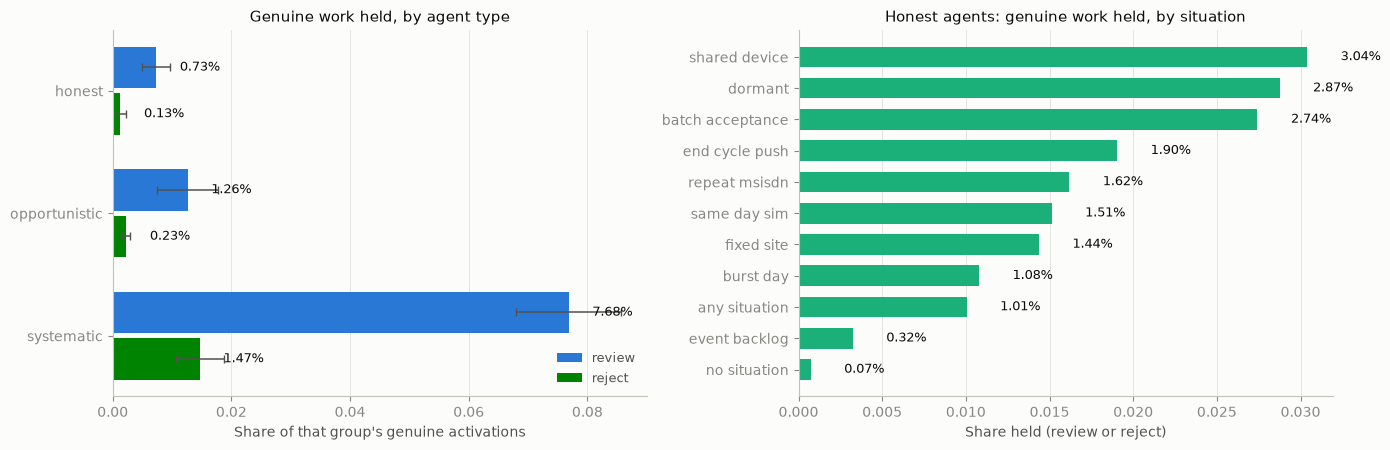

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
order = ["honest", "opportunistic", "systematic"]
bands = ["review", "reject"]
colour = dict(zip(bands, [SLOTS[0], SLOTS[5]]))
pivot = fair_honesty.pivot_table(index="honesty_type", columns="band", values="share_mean").reindex(order)
errors = fair_honesty.pivot_table(index="honesty_type", columns="band", values="share_sd_across_seeds").reindex(order)
base = np.arange(len(order))[::-1]
for offset, band in zip((0.19, -0.19), bands):
    axes[0].barh(base + offset, pivot[band], height=0.34, color=colour[band], label=band,
                 xerr=errors[band], error_kw={"ecolor": INK_2, "elinewidth": 1.1, "capsize": 3})
    for y, value in zip(base + offset, pivot[band]):
        axes[0].text(value + 0.004, y, f"{value:.2%}", va="center", fontsize=9, color=INK)
axes[0].set_yticks(base, order)
axes[0].set(xlabel="Share of that group's genuine activations", title="Genuine work held, by agent type")
axes[0].grid(axis="y", visible=False)
axes[0].legend(fontsize=9, loc="lower right")

honest = fair_situation[(fair_situation["population"] == "honest agents only") & (fair_situation["band"] != "auto-released")]
held = honest.groupby("situation")["share_mean"].sum().sort_values()
positions = np.arange(len(held))
axes[1].barh(positions, held.to_numpy(), height=0.66, color=SLOTS[2])
axes[1].set_yticks(positions, [s.replace("_", " ") for s in held.index])
for y, value in zip(positions, held.to_numpy()):
    axes[1].text(value + 0.002, y, f"{value:.2%}", va="center", fontsize=9, color=INK)
axes[1].set(xlabel="Share held (review or reject)", title="Honest agents: genuine work held, by situation")
axes[1].grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIGURES / "fairness_bands.png", dpi=120)
plt.show()

In [24]:
fair_situation[fair_situation["band"] != "auto-released"].pivot_table(
    index=["population", "situation"], columns="band", values="share_mean").round(5)

band                                       reject   review
population              situation                         
all genuine activations any_situation     0.00373  0.01980
                        batch_acceptance  0.00996  0.03887
                        burst_day         0.00397  0.01931
                        dormant           0.01046  0.05305
                        end_cycle_push    0.00701  0.03440
                        event_backlog     0.00160  0.01044
                        fixed_site        0.00274  0.01163
                        no_situation      0.00025  0.00301
                        repeat_msisdn     0.00539  0.02932
                        same_day_sim      0.00654  0.02298
                        shared_device     0.00761  0.02278
honest agents only      any_situation     0.00149  0.00856
                        batch_acceptance  0.00557  0.02185
                        burst_day         0.00167  0.00912
                        dormant           0.00434  0.02440
                        end_cycle_push    0.00270  0.01634
                        event_backlog         NaN  0.00324
                        fixed_site        0.00274  0.01163
                        no_situation      0.00021  0.00052
                        repeat_msisdn     0.00323  0.01295
                        same_day_sim      0.00313  0.01200
                        shared_device     0.00761  0.02278

### Part E3: how long the money is held

Waiting time uses an M/D/1 queue (Poisson arrivals, fixed nine-minute reviews),
a standard approximation rather than a measurement.

**The queue is still not where the harm is.** The review band takes 3.0% of
volume against 7.9% of capacity, utilisation is 0.38 and the mean wait is 0.008
days, about eleven minutes. The harm remains refusal rather than delay, which is
exactly why pricing the two identically was wrong.

In [25]:
display(fair_delay.round(4))
fair_queue.round(4)

,honesty_type,auto-released,reject,review,expected_extra_delay_days,share_withheld_pending_appeal,note
0,honest,0.9914,0.0013,0.0073,0.0001,0.0013,review adds 0.01 days on average; a rejected g...
1,opportunistic,0.9851,0.0023,0.0126,0.0001,0.0023,review adds 0.01 days on average; a rejected g...
2,systematic,0.9085,0.0147,0.0768,0.0006,0.0147,review adds 0.01 days on average; a rejected g...


,review_share_of_volume,daily_activations,daily_review_arrivals,daily_review_capacity,utilisation,mean_wait_days_for_a_reviewed_activation,model
0,0.0296,508.996,15.0667,40,0.3767,0.0076,"M/D/1, Poisson arrivals and fixed review time"


### Part E4: did the correction help the people it was meant to help?

**Yes, substantially, and in much the same proportion for every group.** Outright
refusal of genuine work fell by about three quarters across the board: honest
agents from 0.49% to 0.13%, opportunistic from 0.77% to 0.23%, systematic from
5.71% to 1.47%. Honest work carrying a lookalike situation is held less often
too: a shared team device from 4.78% to 3.04%, batch acceptance from 4.73% to
2.74%.

Two things did not change, and both should be said plainly:

- **The gap between agent types is untouched.** A systematic agent's genuine activation is still refused about eleven times as often as an honest agent's (1.47% against 0.13%, against 11.6 times before). The correction lowered the whole curve; it did not flatten it.
- **Honest agents with no lookalike situation remain the least affected** (0.07% held), and those whose legitimate working patterns resemble fraud still carry the cost. Splitting the false positive changed how much that costs them, not who pays.

In [26]:
comparison_honesty = read("comparison_fairness_by_honesty")
display(comparison_honesty.round(5))
held = read("comparison_fairness_held_totals")
held[held["population"] == "honest agents only"].round(5)

,honesty_type,band,share_mean_phase5,share_mean_phase6,change,relative_change,share_sd_across_seeds_phase6
0,honest,auto-released,0.98592,0.99142,0.00549,0.00557,0.00321
1,opportunistic,auto-released,0.97796,0.98511,0.00715,0.00731,0.00549
2,systematic,auto-released,0.87286,0.90848,0.03561,0.04080,0.00664
3,honest,reject,0.00492,0.00127,-0.00365,-0.74152,0.00090
4,opportunistic,reject,0.00774,0.00227,-0.00547,-0.70687,0.00063
5,systematic,reject,0.05712,0.01469,-0.04244,-0.74292,0.00403
6,honest,review,0.00916,0.00731,-0.00184,-0.20145,0.00238
7,opportunistic,review,0.01430,0.01262,-0.00168,-0.11727,0.00509
8,systematic,review,0.07001,0.07684,0.00683,0.09752,0.00888


,population,situation,share_mean_phase5,share_mean_phase6,change
5,honest agents only,shared_device,0.04782,0.03039,-0.01742
7,honest agents only,dormant,0.04550,0.02874,-0.01675
8,honest agents only,batch_acceptance,0.04733,0.02743,-0.01990
11,honest agents only,end_cycle_push,0.02984,0.01905,-0.01080
12,honest agents only,repeat_msisdn,0.02459,0.01618,-0.00840
13,honest agents only,same_day_sim,0.02424,0.01513,-0.00911
15,honest agents only,fixed_site,0.02362,0.01437,-0.00925
17,honest agents only,burst_day,0.01739,0.01079,-0.00660
18,honest agents only,any_situation,0.01650,0.01005,-0.00645
20,honest agents only,event_backlog,0.00474,0.00324,-0.00150


## What this session establishes, and what it does not

**Established.**

- Isotonic calibration makes the probabilities honest (ECE 0.0067), so band cutoffs mean what they say.
- Measured as auto-release volume at a 99% pure released set, the seven-day hold raises releasable volume from 57.4% to 73.3%. That is the metric the hold window should be judged on, and a much stronger case than the PR-AUC gap suggested.
- Under the corrected cost model the system releases 93.7%, reviews 3.0% and refuses 3.3%, at 0.106 commissions per activation against 0.182 for releasing everything untouched.
- Correcting the cost model cut outright refusal of genuine work by about three quarters, without changing the relative gap between agent types.

**Not established.**

- **The three-band design depends on an unsourced number.** Below about KSh 50 per commission the middle band does not exist. The assumed value is KSh 81.
- **The reject cost is a value judgement, not a measurement.** Setting it above the fraud cost states that wrongly refusing honest earnings is worse than paying one fraud. Every band position follows from that choice, and a client who disagrees gets different bands.
- **Review accuracy is assumed.** 85% sensitivity and 95% specificity are guesses, and both move the thresholds materially.
- **The cost of a false positive still falls on honest agents whose legitimate working patterns resemble fraud**, and nothing in this session addresses that.